# Detección de objetos con webcam + YOLO

## Instalación de YOLO


In [ ]:
!pip -q install ultralytics

# Importar librerías

In [ ]:
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode
from ultralytics import YOLO
import cv2
from google.colab.patches import cv2_imshow

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


## Función para tomar una foto con la webcam (en el navegador)

<IPython.core.display.Javascript object>

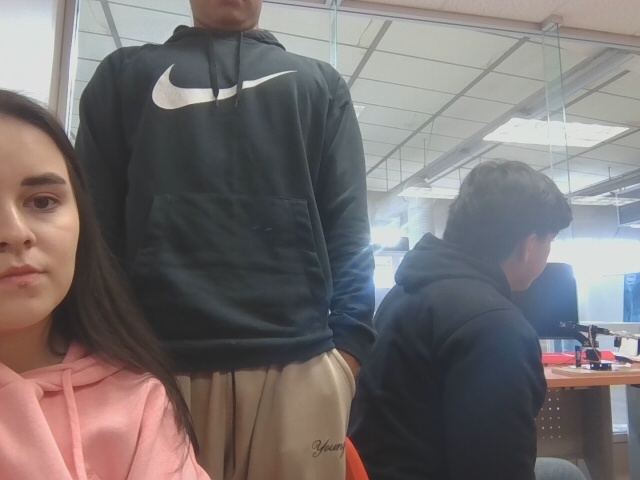

In [ ]:
def tomar_foto(nombre='foto.jpg', calidad=0.95):
    js = Javascript('''
    async function takePhoto(quality) {
      const div = document.createElement('div');
      const boton = document.createElement('button');
      boton.textContent = 'Capturar';
      div.appendChild(boton);
      const video = document.createElement('video');
      video.style.display = 'block';
      const stream = await navigator.mediaDevices.getUserMedia({video: true});
      document.body.appendChild(div);
      div.appendChild(video);
      video.srcObject = stream;
      await video.play();
      google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);
      await new Promise((resolve) => boton.onclick = resolve);
      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      stream.getVideoTracks()[0].stop();
      div.remove();
      return canvas.toDataURL('image/jpeg', quality);
    }
    ''')
    display(js)
    data = eval_js('takePhoto({})'.format(calidad))
    with open(nombre, 'wb') as f:
        f.write(b64decode(data.split(',')[1]))
    return nombre

ruta = tomar_foto('foto.jpg')
from IPython.display import Image
Image(ruta)

## Detección con un modelo preentrenado (80 clases COCO: botella, taza, tijeras, etc.)

Imagen: 640x480 px
person       conf=0.91  centro=(225, 239) px  caja=(72,1,377,478)
person       conf=0.91  centro=(464, 320) px  caja=(349,160,579,480)
person       conf=0.91  centro=(105, 285) px  caja=(1,91,210,479)


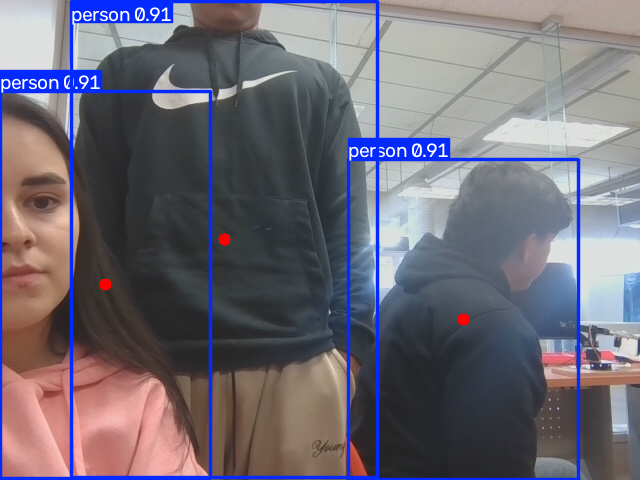

In [ ]:
model = YOLO('yolo11n.pt')

def detectar(ruta, conf=0.4, solo=None):
    """solo: lista de nombres de clase a conservar, p. ej. ['bottle', 'cup']"""
    res = model(ruta, conf=conf, verbose=False)[0]
    img = res.plot()
    h, w = img.shape[:2]
    print(f'Imagen: {w}x{h} px')
    resultados = []
    for box in res.boxes:
        nombre = model.names[int(box.cls)]
        if solo and nombre not in solo:
            continue
        x1, y1, x2, y2 = box.xyxy[0].tolist()
        cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
        print(f'{nombre:12s} conf={float(box.conf):.2f}  centro=({cx:.0f}, {cy:.0f}) px  caja=({x1:.0f},{y1:.0f},{x2:.0f},{y2:.0f})')
        cv2.circle(img, (int(cx), int(cy)), 6, (0, 0, 255), -1)
        resultados.append((nombre, cx, cy))
    cv2_imshow(img)
    return resultados

detecciones = detectar(ruta)